# 导入Python库

In [4]:
import numpy as np
from scipy.linalg import eigh
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, Rectangle

# 读取输入文件input.txt

In [5]:
nodes = {}
elements = {}
constrained_nodes = []
E = A = rho = None
    
with open('../../input/Truss 3.txt', 'r') as f:
    # 读取材料参数
    material_line = f.readline().split()
    E = float(material_line[0])
    A = float(material_line[1])
    rho = float(material_line[2])
        
    # 读取节点信息
    n_nodes = int(f.readline().strip())
    for _ in range(n_nodes):
        node_data = f.readline().split()
        node_id = int(node_data[0])
        x = float(node_data[1])
        y = float(node_data[2])
        nodes[node_id] = [x, y]
        
    # 读取单元信息
    n_elements = int(f.readline().strip())
    for _ in range(n_elements):
        elem_data = f.readline().split()
        elem_id = int(elem_data[0])
        i = int(elem_data[1])
        j = int(elem_data[2])
        elements[elem_id] = [i, j]
        
    # 读取约束节点
    constrained_line = f.readline().split()
    constrained_nodes = [int(node) for node in constrained_line]

# 绘制节点和单元示意图

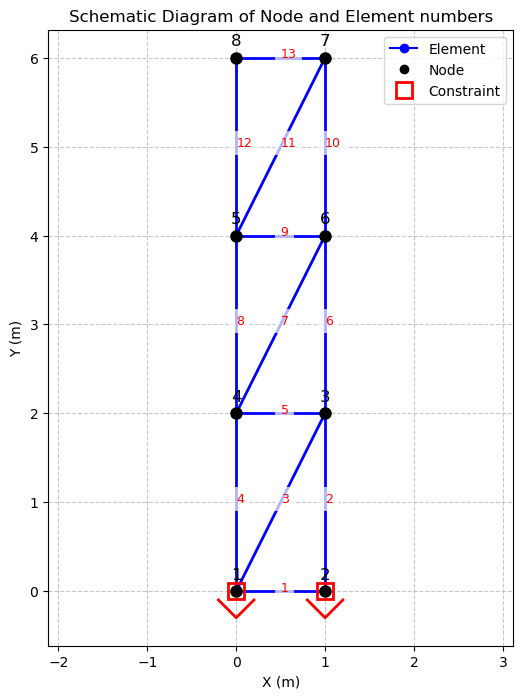

In [6]:
def plot_truss_structure(nodes, elements, constrained_nodes, title="无振动结构", filename=None):
    plt.figure(figsize=(6, 8))
    
    # 绘制单元
    for elem_id, (i, j) in elements.items():
        xi, yi = nodes[i]
        xj, yj = nodes[j]
        plt.plot([xi, xj], [yi, yj], 'b-o', linewidth=2, markersize=6)
        # 标注单元号
        mid_x = (xi + xj) / 2
        mid_y = (yi + yj) / 2
        plt.text(mid_x, mid_y, f"{elem_id}", fontsize=9, color='red', 
                 bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))
    
    # 绘制节点并标注节点号
    for node_id, (x, y) in nodes.items():
        plt.plot(x, y, 'ko', markersize=8)
        plt.text(x, y+0.1, f"{node_id}", fontsize=12, ha='center', va='bottom')
    
    # 绘制约束
    for node_id in constrained_nodes:
        x, y = nodes[node_id]
        # 绘制固定支座
        plt.plot(x, y, 'rs', markersize=12, markerfacecolor='none', markeredgewidth=2)
        # 绘制支座三角形
        triangle_height = 0.3
        plt.plot([x-0.2, x, x+0.2], [y-0.1, y-triangle_height, y-0.1], 'r-', linewidth=2)
    
    # 设置坐标轴
    plt.xlabel('X (m)')
    plt.ylabel('Y (m)')
    plt.title(title)
    plt.grid(True, linestyle='--', alpha=0.7)
    plt.axis('equal')
    
    # 添加图例
    plt.plot([], [], 'b-o', label='Element')
    plt.plot([], [], 'ko', label='Node')
    plt.plot([], [], 'rs', markersize=12, markerfacecolor='none', markeredgewidth=2, label='Constraint')
    plt.legend(loc='best')
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    plt.show()

plot_truss_structure(nodes, elements, constrained_nodes, 
                         title=f"Schematic Diagram of Node and Element numbers",
                         filename="../../output/Truss 3/structure.png")

# 求解

In [7]:
# 计算自由度数
n_nodes = len(nodes)
dofs_per_node = 2
total_dofs = n_nodes * dofs_per_node

# 定义全局刚度矩阵和质量矩阵
K = np.zeros((total_dofs, total_dofs))
M = np.zeros((total_dofs, total_dofs))

# 组装全局刚度矩阵和质量矩阵
for elem_id, (i, j) in elements.items():
    # 获取节点坐标
    xi, yi = nodes[i]
    xj, yj = nodes[j]
        
    # 计算单元长度和方向余弦
    dx = xj - xi
    dy = yj - yi
    L = np.sqrt(dx**2 + dy**2)
    c = dx / L
    s = dy / L
        
    # 单元刚度矩阵
    k_e = (E * A / L) * np.array([
        [1, -1],
        [-1, 1]
    ])
        
    # 转换矩阵R
    R = np.array([
        [c, s, 0, 0],
        [0, 0, c, s]
    ])
        
    # 全局刚度矩阵 (4x4)
    k_global = R.T @ k_e @ R
        
    # 装配到全局矩阵
    dofs = [2*(i-1), 2*(i-1)+1, 2*(j-1), 2*(j-1)+1]
    for idx1, d1 in enumerate(dofs):
        for idx2, d2 in enumerate(dofs):
            K[d1, d2] += k_global[idx1, idx2]
        
    # 集中质量矩阵
    mass = rho * A * L / 2
    M[2*(i-1), 2*(i-1)] += mass
    M[2*(i-1)+1, 2*(i-1)+1] += mass
    M[2*(j-1), 2*(j-1)] += mass
    M[2*(j-1)+1, 2*(j-1)+1] += mass

# 边界条件
constrained_dofs = []
for node in constrained_nodes:
    constrained_dofs.append(2*(node-1))    # x方向
    constrained_dofs.append(2*(node-1)+1)  # y方向

free_dofs = [i for i in range(total_dofs) if i not in constrained_dofs]

# 提取子矩阵
K_reduced = K[np.ix_(free_dofs, free_dofs)]
M_reduced = M[np.ix_(free_dofs, free_dofs)]

# 求解
eigenvalues, eigenvectors = eigh(K_reduced, M_reduced)
frequencies = np.sqrt(eigenvalues) / (2 * np.pi)

# 绘制振型图

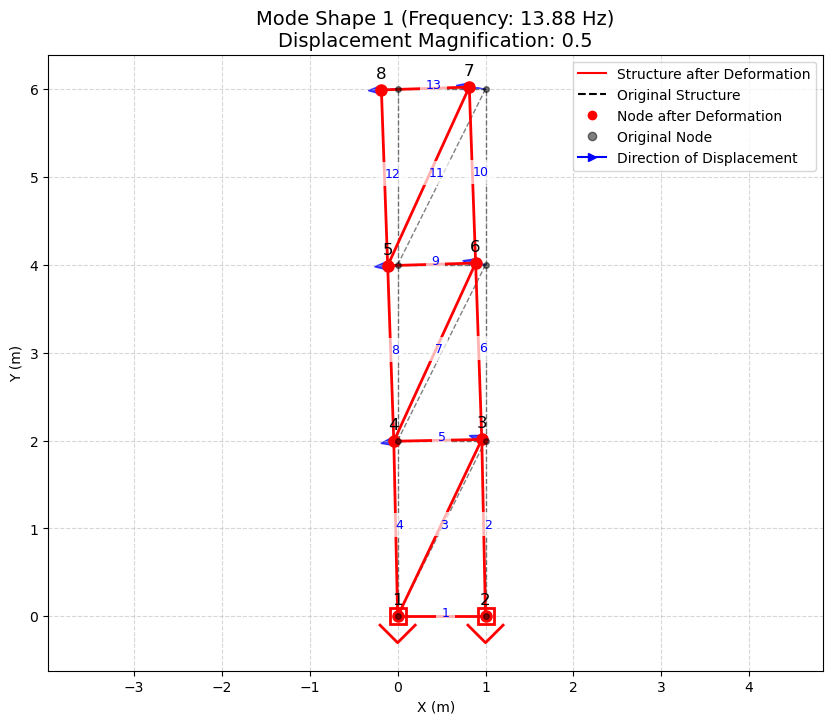

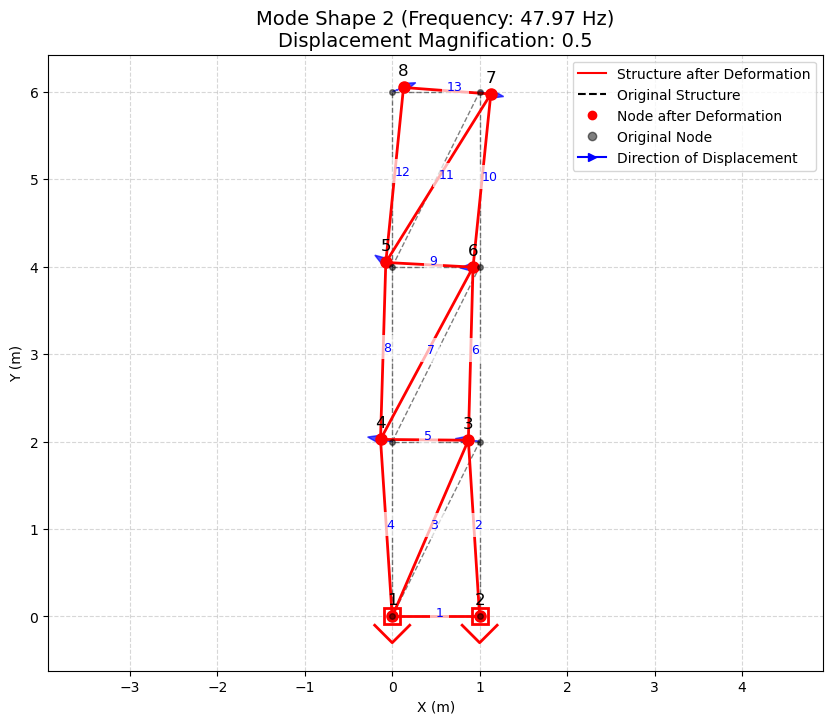

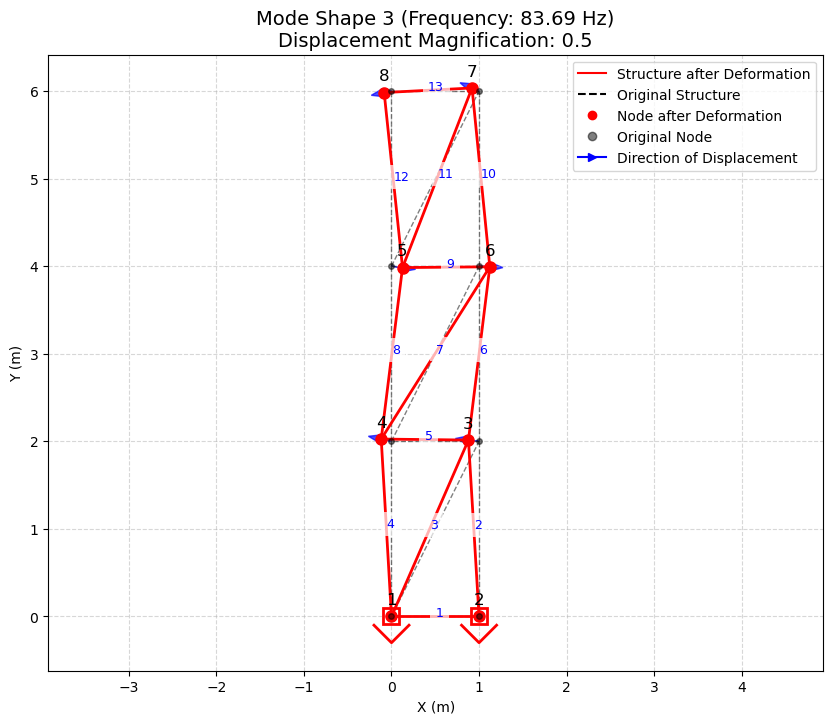

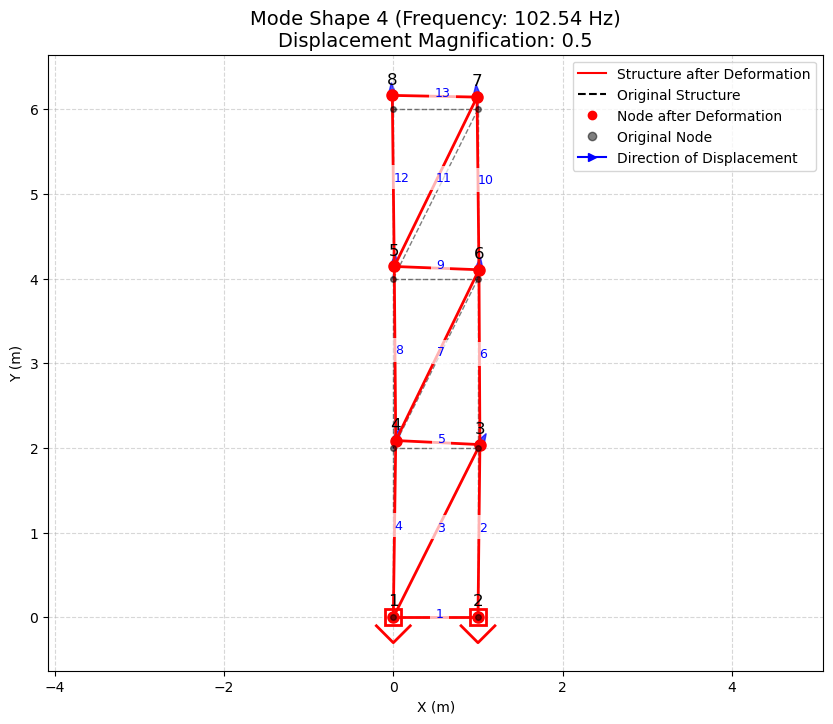

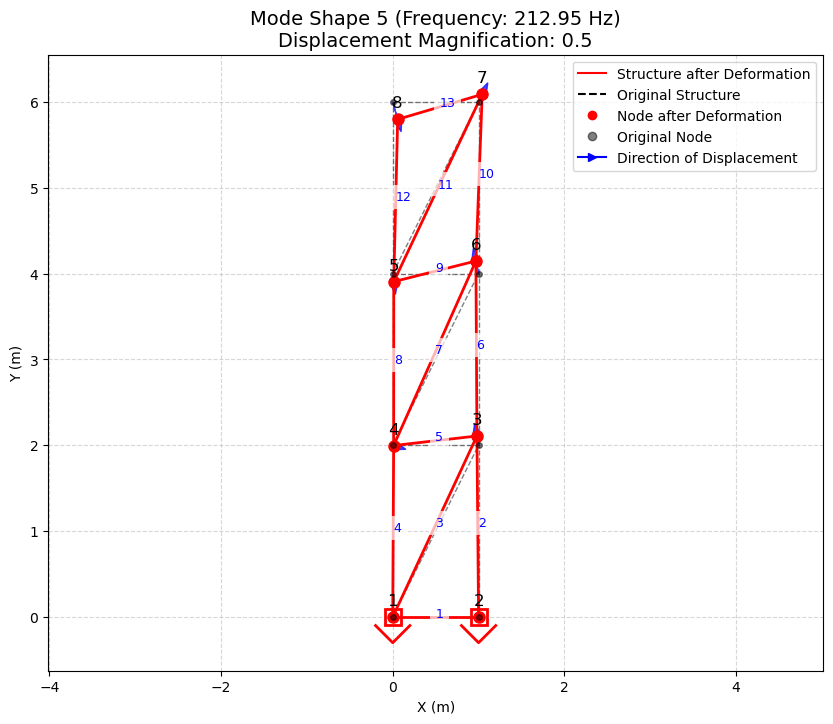

In [8]:
def plot_mode_shapes(nodes, elements, constrained_nodes, eigenvectors, frequencies, free_dofs, scale_factor=5):
    n_modes = min(5, len(frequencies))  # 最多绘制5阶振型
    
    for mode in range(n_modes):
        plt.figure(figsize=(10, 8))
        freq = frequencies[mode]
        eigenvector = eigenvectors[:, mode]
        
        # 创建变形后的节点坐标
        deformed_nodes = {}
        for node_id, (x, y) in nodes.items():
            idx_x = 2*(node_id-1)
            idx_y = 2*(node_id-1)+1
            
            # 获取位移（如果该自由度被约束，位移为0）
            dx = eigenvector[free_dofs.index(idx_x)] * scale_factor if idx_x in free_dofs else 0
            dy = eigenvector[free_dofs.index(idx_y)] * scale_factor if idx_y in free_dofs else 0
            
            deformed_nodes[node_id] = [x + dx, y + dy]
        
        # 绘制原始结构（灰色）
        for i, j in elements.values():
            xi, yi = nodes[i]
            xj, yj = nodes[j]
            plt.plot([xi, xj], [yi, yj], 'k--', linewidth=1, alpha=0.5)
        
        # 绘制振动时最大位移的结构（红色）
        for elem_id, (i, j) in elements.items():
            xi, yi = deformed_nodes[i]
            xj, yj = deformed_nodes[j]
            plt.plot([xi, xj], [yi, yj], 'r-', linewidth=2)
            
            # 标注单元号
            mid_x = (xi + xj) / 2
            mid_y = (yi + yj) / 2
            plt.text(mid_x, mid_y, f"{elem_id}", fontsize=9, color='blue', 
                     bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))
        
        # 绘制变形后的节点
        for node_id, (x, y) in deformed_nodes.items():
            plt.plot(x, y, 'ro', markersize=8)
            plt.text(x, y+0.1, f"{node_id}", fontsize=12, ha='center', va='bottom')
        
        # 绘制原始节点位置（灰色）
        for node_id, (x, y) in nodes.items():
            plt.plot(x, y, 'ko', markersize=4, alpha=0.5)
        
        # 绘制约束
        for node_id in constrained_nodes:
            x, y = nodes[node_id]
            plt.plot(x, y, 'rs', markersize=12, markerfacecolor='none', markeredgewidth=2)
            triangle_height = 0.3
            plt.plot([x-0.2, x, x+0.2], [y-0.1, y-triangle_height, y-0.1], 'r-', linewidth=2)
        
        # 添加位移向量箭头
        for node_id, (x, y) in nodes.items():
            idx_x = 2*(node_id-1)
            idx_y = 2*(node_id-1)+1
            
            if idx_x in free_dofs and idx_y in free_dofs:
                dx = eigenvector[free_dofs.index(idx_x)] * scale_factor
                dy = eigenvector[free_dofs.index(idx_y)] * scale_factor
                
                # 绘制位移向量
                plt.arrow(x, y, dx, dy, head_width=0.1, head_length=0.15, 
                          fc='blue', ec='blue', alpha=0.7)
        
        # 设置标题和标签
        plt.title(f"Mode Shape {mode+1} (Frequency: {freq:.2f} Hz)\nDisplacement Magnification: {scale_factor}", fontsize=14)
        plt.xlabel('X (m)')
        plt.ylabel('Y (m)')
        plt.grid(True, linestyle='--', alpha=0.5)
        plt.axis('equal')
        
        # 添加图例
        plt.plot([], [], 'r-', label='Structure after Deformation')
        plt.plot([], [], 'k--', label='Original Structure')
        plt.plot([], [], 'ro', label='Node after Deformation')
        plt.plot([], [], 'ko', alpha=0.5, label='Original Node')
        plt.plot([], [], 'b->', label='Direction of Displacement')
        plt.legend(loc='best')
        
        # 保存图像
        filename = f"../../output/Truss 3/{mode+1}.png"
        plt.savefig(filename, dpi=300, bbox_inches='tight')
        plt.show()

plot_mode_shapes(nodes, elements, constrained_nodes, eigenvectors, frequencies, 
                     free_dofs, scale_factor=0.5)

# 输出结果到output.txt

In [9]:
with open('../../output/Truss 3/output.txt', "w") as f:
    for mode in range(min(5, len(frequencies))):
        f.write(f"\n振型 {mode+1} (频率: {frequencies[mode]:.4f} Hz):\n")
        full_vector = np.zeros(total_dofs)
        full_vector[free_dofs] = eigenvectors[:, mode]
            
        for node_id in range(1, n_nodes+1):
            dx = full_vector[2*(node_id-1)]
            dy = full_vector[2*(node_id-1)+1]
            f.write(f"节点 {node_id}: dx = {dx:.6e}, dy = {dy:.6e}\n")